# CUSTOMER CHURN INVESTIGATION

**Project 1 – Arrowstack Data Science Internship**

## 1. Business Problem
Customer churn occurs when customers discontinue a company's services. This project uses Exploratory Data Analysis (EDA) to investigate customer churn patterns in the telecommunications industry and identify factors associated with customer cancellations.

## 2. Dataset Description
The Telco Customer Churn dataset was obtained from Kaggle [1]. It contains **7,043 customer records and 21 columns**, covering customer demographics, subscription details, services, billing information and churn status.

**Dataset:** `WA_Fn-UseC_-Telco-Customer-Churn.csv`

## 3. Project Objectives
- Assess and clean the dataset.
- Investigate customer churn patterns.
- Examine relationships between customer characteristics and churn.
- Segment customers and compare churn rates.
- Develop evidence-based insights and retention recommendations.

## 4. Primary Stakeholder
**Customer Retention Manager**

The analysis aims to support customer retention decisions by identifying customer groups that may require targeted attention.

## 5. Tools and Technologies
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

## 6. Project Workflow
1. Data acquisition and inspection.
2. Data quality assessment.
3. Data cleaning and preprocessing.
4. Data dictionary development.
5. Exploratory Data Analysis.
6. Customer segmentation.
7. Insights and recommendations.
8. Validation and documentation.

## 7. Expected Deliverables
- Cleaned dataset and data dictionary.
- Data quality assessment.
- EDA tables and visualisations.
- Customer segmentation and business insights.
- Retention recommendations.
- Final project documentation.

## 8. Scope and Limitations
The project uses a public Kaggle dataset representing a simulated telecommunications business scenario. Findings will identify associations with churn, not prove causation.


In [25]:
# import necessary libraries
import pandas as pd
import numpy as np
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

In [26]:
#Loading Dataset
#Panda will be used to read dataset and preprocess it.
df = pd.read_csv(r"C:\Users\janef\OneDrive\Desktop\Arrowstack_Internship\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.shape


(7043, 21)

## Initial Data Inspection

In [27]:
#First five rows of the dataset
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [48]:
#Last five rows of the dataset
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.50,No


In [29]:
df.shape

(7043, 21)

My dataset has 7,043 rows (customer records) and 21 columns.

In [30]:
df.size

147903

In [24]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Total charges is obverved to be object. It supposed to be a float datatype.

In [11]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [34]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
df.duplicated().sum()

0

Data Cleaning

The TotalCharges column was initially stored as an object (text) data type, although it represents numerical values. This will be converted to a floating-point (float) data type during data cleaning to enable accurate numerical analysis.

In [38]:
df['TotalCharges'].dtype

dtype('O')

In [41]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'],errors = 'coerce')

In [42]:
df['TotalCharges'].dtype

dtype('float64')

In [45]:
# Categorical features
categorical_features = df.select_dtypes(include=['object']).columns.tolist()
categorical_features.remove('customerID')
categorical_features.remove('Churn')

# Numerical features
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Target variable
target_variable = 'Churn'

# Display results
print("Categorical Features:", categorical_features)
print("\nNumerical Features:", numerical_features)
print("\nTarget Variable:", target_variable)

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Target Variable: Churn


## Identification of Variables

- **Categorical Features:** gender, Partner, Dependents, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling and PaymentMethod.

- **Numerical Features:** SeniorCitizen, tenure, MonthlyCharges and TotalCharges.

- **Target Variable:** Churn.

These variables were identified to support the exploratory data analysis.

In [46]:
df.skew(numeric_only= True)

SeniorCitizen     1.833633
tenure            0.239540
MonthlyCharges   -0.220524
TotalCharges      0.961642
dtype: float64

In [47]:
df.corr(numeric_only= True)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000000,0.016567,0.220173,0.102411
tenure,0.016567,1.000000,0.247900,0.825880
MonthlyCharges,0.220173,0.247900,1.000000,0.651065
TotalCharges,0.102411,0.825880,0.651065,1.000000


In [49]:
# Check missing values in each column
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [50]:
# Inspect records with missing TotalCharges
df.loc[df['TotalCharges'].isnull(),
       ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [51]:
# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df['customerID'].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [52]:
# Check whether missing TotalCharges records have zero tenure
df.loc[df['TotalCharges'].isnull(), 'tenure'].eq(0).all()

True

Handling Missing Values.

In [54]:
# Replace missing TotalCharges values with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [55]:
# Confirm that there are no remaining missing values
df.isnull().sum().sum()

0

### Data Cleaning Summary

- Converted `TotalCharges` from object to numeric format.
- Identified 11 missing values in `TotalCharges`.
- Confirmed that all affected customers had zero months of tenure.
- Replaced the missing `TotalCharges` values with 0.
- Checked for duplicate records and duplicate customer IDs; none were found.

The dataset is now ready for further exploratory analysis.

## Data Dictionary

## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to examine customer characteristics, identify patterns in customer churn and investigate factors associated with customer cancellations.

The analysis focuses on answering business questions that can help the Customer Retention Manager make informed customer retention decisions.

### Customer Churn Distribution

**Business Question:** What proportion of customers have discontinued the company's services compared with those who remain?

This analysis examines the overall distribution of churn to establish a baseline for customer retention.

In [56]:
# Calculate customer counts and percentages
churn_summary = df['Churn'].value_counts().to_frame('Customer Count')

churn_summary['Percentage'] = (
    df['Churn'].value_counts(normalize=True) * 100
)

churn_summary

,Customer Count,Percentage
Churn,,
No,5174,73.463013
Yes,1869,26.536987


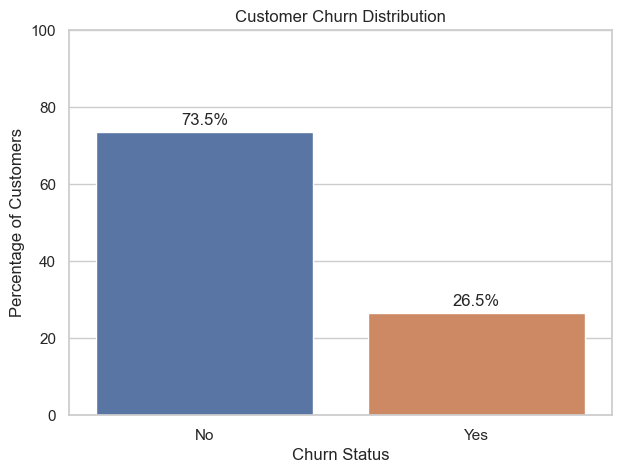

In [57]:
# Visualise customer churn distribution
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=churn_summary.index,
    y=churn_summary['Percentage']
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Percentage of Customers')
plt.ylim(0, 100)
plt.show()

**Interpretation:**

The bar chart of customer churn distribution shows that 73.5% (5,174) of customers remained with the company, while 26.5% (1,869) discontinued their services.

Although most customers remained, approximately one in four customers churned. This highlights the need for effective customer retention strategies.

**Business Implication:**

The Customer Retention Manager should investigate the characteristics and behaviours of customers who churn to identify high-risk customer groups and develop targeted retention strategies.

## Customer Churn by Contract Type

**Business Question:** How does customer churn differ across month-to-month, one-year and two-year contracts?

This analysis compares churn rates across contract types to identify customer groups that may require targeted retention strategies.

In [58]:
# Calculate churn rates by contract type
contract_churn = (
    df.groupby('Contract')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='Churn Rate (%)')
)

contract_churn

,Contract,Churn Rate (%)
0,Month-to-month,42.709677
1,One year,11.269518
2,Two year,2.831858


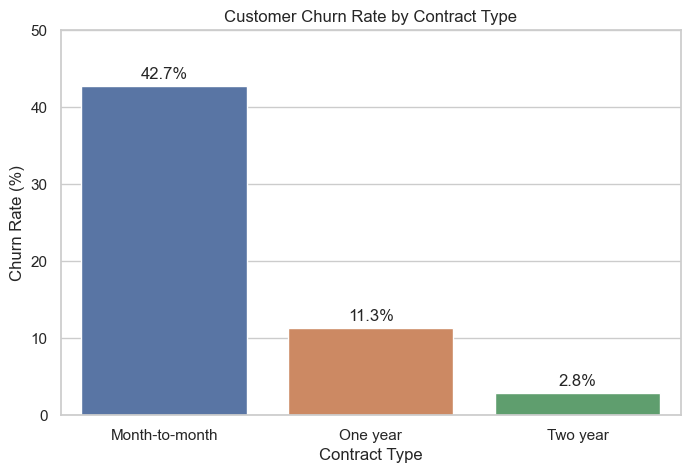

In [59]:
# Visualise churn rate by contract type
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=contract_churn,
    x='Contract',
    y='Churn Rate (%)'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Customer Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 50)
plt.show()

**Interpretation:**

The bar chart shows that month-to-month customers have the highest churn rate at 42.7%, followed by one-year contract customers at 11.3%. Two-year contract customers have the lowest churn rate at 2.8%.

This suggests that longer-term contracts are associated with better customer retention, while customers on flexible month-to-month contracts are more likely to leave.

**Business Implication:**

The Customer Retention Manager should prioritise month-to-month customers for retention initiatives and consider offering incentives to encourage longer-term contracts.

These findings show an association between contract type and churn, not proof that longer contracts cause customers to stay.

## Customer Churn by Tenure

**Business Question:** Is customer tenure associated with the likelihood of churn?

This analysis compares the length of time customers have stayed with the company across churn groups to identify whether newer customers are more likely to discontinue their services.

In [60]:
# Compare customer tenure by churn status
df.groupby('Churn')['tenure'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


This shows that customers who churned had an average tenure of approximately 18 months, compared with approximately 38 months for customers who stayed.

This suggests that customers with shorter tenures are more likely to churn.

## Customer Churn by Monthly Charges
Business Question: Do customers who churn pay higher monthly charges than customers who stay?

In [61]:
df.groupby('Churn')['MonthlyCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


**Interpretation:**

Customers who churned had a higher average monthly charge (74.44) than customers who remained (61.27). The median monthly charge was also higher among customers who churned (79.65) compared with those who stayed (64.43).

This suggests that customers paying higher monthly charges may be more likely to discontinue their services.

**Business Implication:**

The Customer Retention Manager should review pricing and service value, particularly for customers with higher monthly bills. Targeted offers and suitable service packages may help improve customer retention.

These findings show an association, not proof that higher charges cause churn.

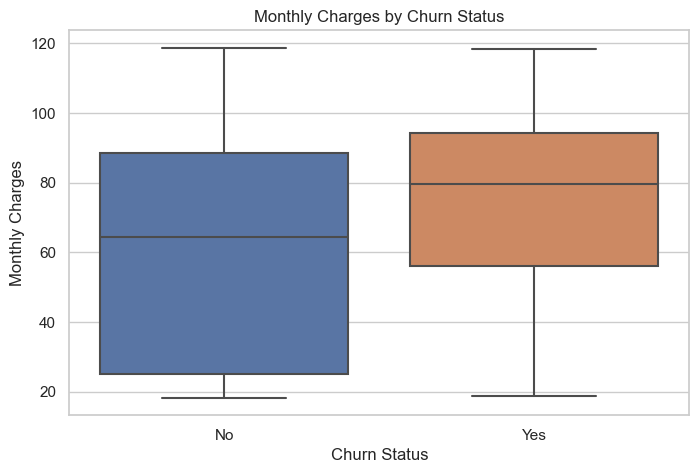

In [62]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')
plt.show()

The box plot further supports this finding, showing that the distribution of monthly charges for customers who churned is generally higher than that of customers who remained.

## Customer Churn by Internet Service Type
Business Question: Does customer churn differ depending on the type of internet service subscribed to?

In [63]:
internet_churn = (
    df.groupby('InternetService')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='Churn Rate (%)')
)

internet_churn

,InternetService,Churn Rate (%)
0,DSL,18.959108
1,Fiber optic,41.892765
2,No,7.404980


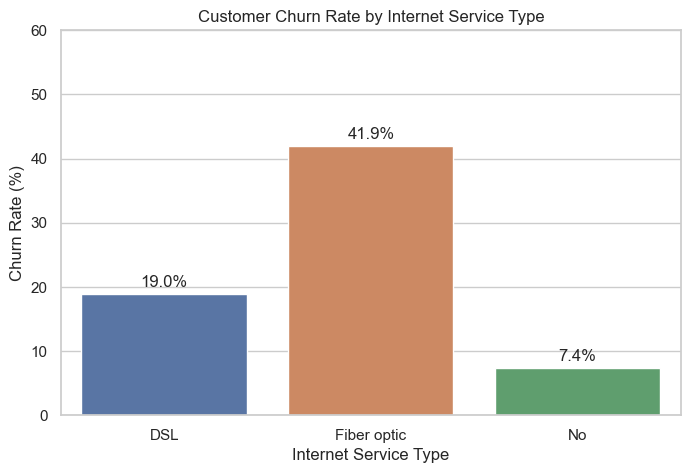

In [64]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=internet_churn,
    x='InternetService',
    y='Churn Rate (%)'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Customer Churn Rate by Internet Service Type')
plt.xlabel('Internet Service Type')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 60)
plt.show()

**Interpretation:**

The bar chart shows that customers using fibre optic internet service have the highest churn rate at 41.9%, followed by DSL customers at 19.0%. Customers without internet service have the lowest churn rate at 7.4%.

This suggests that customers subscribed to fibre optic internet service are more likely to discontinue their services than customers using other service categories.

**Business Implication:**

The Customer Retention Manager should investigate customer satisfaction with fibre optic services, including service quality, pricing and reliability. Targeted support and service improvements may help reduce churn among fibre optic customers.

These findings show an association between internet service type and churn, not proof that fibre optic service causes customers to leave.

## Customer Churn by Payment Method
Business Question: Does customer churn differ depending on the payment method used?

In [65]:
payment_churn = (
    df.groupby('PaymentMethod')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='Churn Rate (%)')
)

payment_churn

,PaymentMethod,Churn Rate (%)
0,Bank transfer (automatic),16.709845
1,Credit card (automatic),15.243101
2,Electronic check,45.285412
3,Mailed check,19.106700


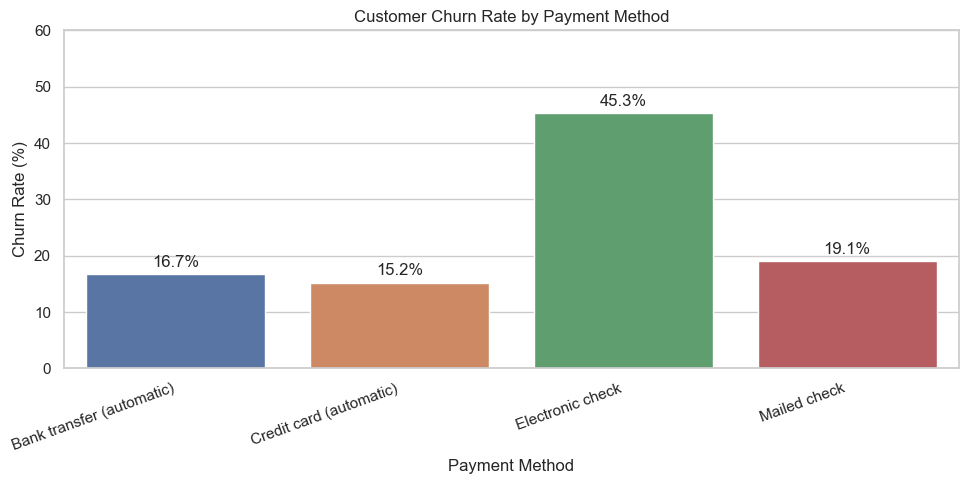

In [66]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=payment_churn,
    x='PaymentMethod',
    y='Churn Rate (%)'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Customer Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, 60)
plt.tight_layout()
plt.show()

**Interpretation:**

The bar chart shows that customers who use electronic check have the highest churn rate at 45.3%, followed by mailed check customers at 19.1%. Customers using bank transfer (automatic) have a churn rate of 16.7%, while credit card (automatic) customers have the lowest churn rate at 15.2%.

This suggests that customers using electronic check are considerably more likely to discontinue their services than customers using automatic payment methods.

**Business Implication:**

The Customer Retention Manager should investigate why electronic check customers have a higher churn rate. Encouraging customers to use automatic payment methods through convenient payment options and suitable incentives may help improve customer retention.

These findings show an association between payment method and churn, not proof that payment method causes customers to leave.

## Customer Churn by Technical Support
Customer support may influence customer satisfaction and retention.

In [67]:
support_churn = (
    df.groupby('TechSupport')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='Churn Rate (%)')
)

support_churn

,TechSupport,Churn Rate (%)
0,No,41.635474
1,No internet service,7.404980
2,Yes,15.166341


**Interpretation:**

The bar chart shows that customers without technical support have the highest churn rate at 41.6%. Customers who receive technical support have a lower churn rate of 15.2%, while customers without internet service have the lowest churn rate at 7.4%.

This suggests that access to technical support is associated with better customer retention.

**Business Implication:**

The Customer Retention Manager should consider improving access to technical support, particularly for customers who currently do not receive this service. Proactive assistance and accessible support options may help reduce customer churn.

These findings show an association between technical support and churn, not proof that technical support causes customers to stay.

## Customer Segmentation

Customer segmentation groups customers according to shared characteristics to identify groups with higher churn rates. This analysis compares contract type and internet service to identify customer segments that may benefit from targeted retention strategies.

In [68]:
segment_churn = (
    df.groupby(['Contract', 'InternetService'])
    .agg(
        Customer_Count=('Churn', 'size'),
        Churn_Rate=('Churn', lambda x: (x == 'Yes').mean() * 100)
    )
    .reset_index()
    .sort_values('Churn_Rate', ascending=False)
)

segment_churn

,Contract,InternetService,Customer_Count,Churn_Rate
1,Month-to-month,Fiber optic,2128,54.605263
0,Month-to-month,DSL,1223,32.215863
4,One year,Fiber optic,539,19.294991
2,Month-to-month,No,524,18.893130
3,One year,DSL,570,9.298246
7,Two year,Fiber optic,429,7.226107
5,One year,No,364,2.472527
6,Two year,DSL,628,1.910828
8,Two year,No,638,0.783699


**Interpretation:**

The customer segmentation analysis shows that month-to-month customers using fibre optic internet have the highest churn rate at 54.6%, followed by month-to-month customers using DSL at 32.2%.

Customers with longer-term contracts generally have lower churn rates. The lowest churn rate of 0.8% is observed among customers with two-year contracts and no internet service.

This suggests that the combination of contract type and internet service is useful for identifying customer groups with different levels of churn risk.

**Business Implication:**

The Customer Retention Manager should prioritise month-to-month fibre optic customers for targeted retention initiatives. These could include proactive customer support, service-quality reviews and suitable contract incentives.

The results show associations between customer characteristics and churn, rather than proving that these characteristics cause customers to leave.

## Key Findings

The exploratory data analysis identified several factors associated with customer churn:

- **Overall churn:** 26.5% of customers discontinued their services.
- **Contract type:** Month-to-month customers had the highest churn rate at 42.7%.
- **Tenure:** Customers who churned had a shorter average tenure (approximately 18 months) than customers who stayed (approximately 38 months).
- **Monthly charges:** Customers who churned had higher average monthly charges (74.44) than customers who stayed (61.27).
- **Internet service:** Fibre optic customers had a churn rate of 41.9%.
- **Payment method:** Electronic check customers had the highest churn rate at 45.3%.
- **Technical support:** Customers without technical support had a churn rate of 41.6%.
- **Customer segments:** Month-to-month customers using fibre optic internet had the highest segment churn rate at 54.6%.

These findings identify customer groups that may benefit from targeted retention strategies.

## Recommendations

Based on the findings, the following actions are recommended:

1. **Improve early customer retention:** Introduce onboarding support and regular follow-ups for new customers.
2. **Encourage longer-term contracts:** Consider suitable incentives for month-to-month customers to move to one-year or two-year contracts.
3. **Review fibre optic services:** Investigate pricing, reliability and customer satisfaction among fibre optic customers.
4. **Review payment methods:** Investigate why electronic check customers have higher churn and encourage convenient automatic payment options.
5. **Improve technical support:** Make support more accessible and provide proactive assistance to customers.
6. **Target high-risk segments:** Prioritise month-to-month fibre optic customers for retention campaigns.

The effectiveness of these recommendations should be measured by monitoring customer churn rates over time.

## Limitations

- The dataset is simulated and may not represent all real-world telecommunications customers.
- The analysis identifies associations, not causal relationships.
- The dataset does not include detailed customer satisfaction, complaints or competitor information.
- The analysis uses a single dataset snapshot and does not track changes in customer behaviour over time.
- Further investigation would be needed to understand the reasons behind the observed churn patterns.

In [69]:
assert df.shape == (7043, 21)
assert df.isnull().sum().sum() == 0
assert df['customerID'].is_unique
assert df.duplicated().sum() == 0
assert set(df['Churn'].unique()) == {'Yes', 'No'}

print("All validation checks passed.")

All validation checks passed.


## Conclusion

This project investigated customer churn in a simulated telecommunications dataset containing 7,043 customer records and 21 columns. The aim was to identify customer characteristics associated with churn, segment customers according to their risk levels and provide evidence-based recommendations to support customer retention decisions.

The exploratory data analysis found that 26.5% of customers had discontinued their services. Several customer characteristics were associated with higher churn rates. Month-to-month customers had a churn rate of 42.7%, compared with 11.3% for one-year contracts and 2.8% for two-year contracts. Customers who churned also had a shorter average tenure of approximately 18 months, compared with 38 months for customers who remained.

Other notable findings included a 45.3% churn rate among electronic check customers, a 41.9% churn rate among fibre optic customers and a 41.6% churn rate among customers without technical support. Customer segmentation identified month-to-month customers using fibre optic internet as the highest-risk group, with a churn rate of 54.6%.

Based on these findings, the project recommends prioritising early customer engagement, reviewing fibre optic service quality and pricing, improving access to technical support, investigating electronic check customer behaviour and encouraging suitable longer-term contract options.

Overall, the project demonstrates how data cleaning, exploratory data analysis and customer segmentation can provide useful insights for business decision-making. The findings offer the Customer Retention Manager a starting point for developing targeted retention strategies. However, the relationships identified are associations rather than evidence of causation. Further investigation using customer satisfaction data, complaints and customer behaviour over time would help validate the findings and assess the effectiveness of the recommended actions.

The project has achieved its main objective of identifying customer groups associated with higher churn and translating the findings into practical business recommendations.

## References

[1] blastchar, "Telco Customer Churn," Kaggle. [Online]. Available: https://www.kaggle.com/datasets/blastchar/telco-customer-churn. [Accessed: Nov. 4, 2026].